# **LSTM RNN - Antarctic Plateau Time Series**

In [1]:
import numpy as np
import pandas as pd

import torch
np.random.seed(42)
torch.manual_seed(42)

In [2]:
dataset = pd.read_csv('apsrht_datetime.csv', index_col='date_time', parse_dates=True).asfreq('15min')['temp_C']
dataset

date_time
2018-12-19 00:00:00   -20.167
2018-12-19 00:15:00   -20.073
2018-12-19 00:30:00   -19.839
2018-12-19 00:45:00   -19.700
2018-12-19 01:00:00   -19.469
                        ...  
2019-02-02 22:45:00   -34.677
2019-02-02 23:00:00   -34.593
2019-02-02 23:15:00   -34.427
2019-02-02 23:30:00   -34.262
2019-02-02 23:45:00   -34.098
Freq: 15min, Name: temp_C, Length: 4416, dtype: float64

### EDA

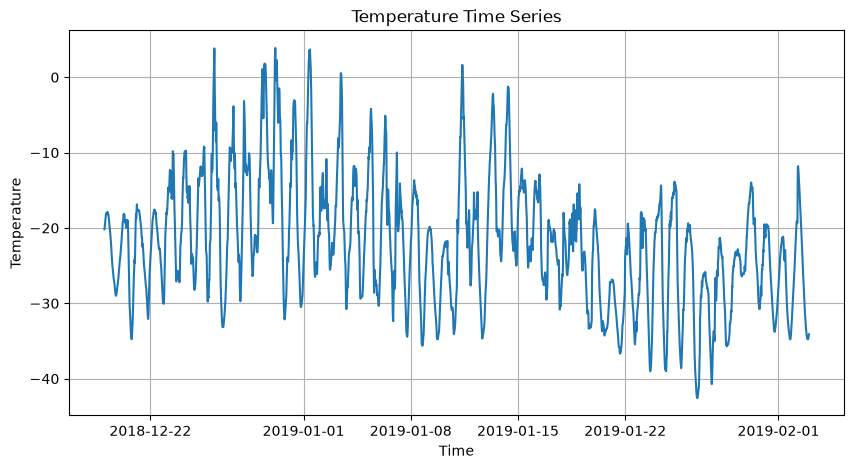

In [3]:
### dataset
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(dataset)
plt.title('Temperature Time Series')
plt.xlabel('Time')
plt.ylabel('Temperature')
plt.grid(True)
plt.show()

In [4]:
print(dataset.info(),'\n')
print(dataset.describe(),'\n')
print(dataset.isnull().sum())

<class 'pandas.Series'>
DatetimeIndex: 4416 entries, 2018-12-19 00:00:00 to 2019-02-02 23:45:00
Freq: 15min
Series name: temp_C
Non-Null Count  Dtype  
--------------  -----  
4416 non-null   float64
dtypes: float64(1)
memory usage: 69.0 KB
None 

count    4416.000000
mean      -21.892046
std         8.369950
min       -42.564000
25%       -27.646000
50%       -22.320000
75%       -16.870000
max         3.880000
Name: temp_C, dtype: float64 

0


### Splitting

In [5]:
### dataset splitting
split_1 = int(len(dataset) * 0.80)
split_2 = int(len(dataset) * 0.90)
train_set = dataset.iloc[:split_1]
validation_set = dataset.iloc[split_1:split_2]
test_set = dataset.iloc[split_2:]

In [6]:
print(f"Training Set Shape: {train_set.shape}")
print(f"Validation Set Shape: {validation_set.shape}")
print(f"Testing Set Shape: {test_set.shape}\n")

Training Set Shape: (3532,)
Validation Set Shape: (442,)
Testing Set Shape: (442,)



In [7]:
print("Train:")
print(train_set.index.min(), "to", train_set.index.max())

print("\nValidation:")
print(validation_set.index.min(), "to", validation_set.index.max())

print("\nTest:")
print(test_set.index.min(), "to", test_set.index.max())

Train:
2018-12-19 00:00:00 to 2019-01-24 18:45:00

Validation:
2019-01-24 19:00:00 to 2019-01-29 09:15:00

Test:
2019-01-29 09:30:00 to 2019-02-02 23:45:00


### Normalization

In [8]:
from sklearn.preprocessing import MinMaxScaler

### scaler is only fit on the training data; otherwise data leakage would occur
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_set.values.reshape(-1, 1))
validation_scaled = scaler.transform(validation_set.values.reshape(-1, 1))
test_scaled = scaler.transform(test_set.values.reshape(-1, 1))

### Windowing

In [9]:
def get_lookback_window(dataset, window_size=60):
    """
    Creates prediction datasets from time series data by splitting into
    "lookback" windows. It looks back 60 measurements to predict the next
    measurement.
    """
    X, y = [], []

    for i in range(len(dataset) - window_size):
        X.append(dataset[i:i + window_size])
        y.append(dataset[i + window_size])

    return np.array(X), np.array(y)

In [10]:
### X, y "lookback" sets for train/val/test respectively
X_train, y_train = get_lookback_window(train_scaled)
X_val, y_val = get_lookback_window(validation_scaled)
X_test, y_test = get_lookback_window(test_scaled)

print(f"Shape of X_train: {X_train.shape}, Shape of y_train: {y_train.shape}")
print(f"Shape of X_val:   {X_val.shape}, Shape of y_val: {y_val.shape}")
print(f"Shape of X_test:  {X_test.shape}, Shape of y_test: {y_test.shape}")

Shape of X_train: (3472, 60, 1), Shape of y_train: (3472, 1)
Shape of X_val:   (382, 60, 1), Shape of y_val: (382, 1)
Shape of X_test:  (382, 60, 1), Shape of y_test: (382, 1)


### Dataloading

In [11]:
from torch.utils.data import TensorDataset, DataLoader

In [12]:
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

In [13]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: torch.Size([3472, 60, 1])
y_train: torch.Size([3472, 1])

X_val: torch.Size([382, 60, 1])
y_val: torch.Size([382, 1])

X_test: torch.Size([382, 60, 1])
y_test: torch.Size([382, 1])


In [14]:
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

In [15]:
X_sample, y_sample = train_dataset[0]

print(X_sample.shape)
print(y_sample.shape)

torch.Size([60, 1])
torch.Size([1])


In [16]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

### Modeling

In [17]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

Device: cpu


In [18]:
import torch.nn as nn

class LSTM(nn.Module):
    def __init__(self):
        super().__init__()
        
        # LSTM layer
        self.lstm = nn.LSTM(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        
        # output layer
        self.fc = nn.Linear(in_features=64, out_features=1)

    def forward(self, X):  # input shape: (batch_size, sequence_length, input_size)
    
        # passes input data into the LSTM
        output, (hidden, cell) = self.lstm(X)
        
        # takes the output from the final time step
        output = output[:, -1, :]
        
        # pass final pattern through linear layer to get predicted temp
        output = self.fc(output)
        
        return output

        

In [19]:
model = LSTM().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [20]:
num_epochs = 50
epoch_losses = []
val_losses = []

for epoch in range(num_epochs):
    
    ### training ###
    model.train()  # set model to train mode
    train_running_loss = 0.0
    
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()  # clear gradients from previous iteration
        predictions = model(X)  # generate model predictions
        loss = criterion(predictions, y)  # compute loss on predictions
        loss.backward()  # back propagation; calculate gradients
        optimizer.step()  # adjust model parameters based on gradients
        train_running_loss += loss.item()
    
    epoch_loss = train_running_loss / len(train_loader)
    epoch_losses.append(epoch_loss)
    

    ### validation ###
    model.eval()
    val_running_loss = 0.0
    
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            predictions = model(X)
            loss = criterion(predictions, y)
            val_running_loss += loss.item()

    val_loss = val_running_loss / len(val_loader)
    val_losses.append(val_loss)
    
    print(f'=== Epoch {epoch + 1}/{num_epochs} ===')
    print(f'Training Loss: {epoch_loss:.6f} --- Validation Loss: {val_loss:.6f}\n')



=== Epoch 1/50 ===
Training Loss: 0.044286 --- Validation Loss: 0.022910

=== Epoch 2/50 ===
Training Loss: 0.005997 --- Validation Loss: 0.004307

=== Epoch 3/50 ===
Training Loss: 0.002740 --- Validation Loss: 0.002182

=== Epoch 4/50 ===
Training Loss: 0.002082 --- Validation Loss: 0.001562

=== Epoch 5/50 ===
Training Loss: 0.001788 --- Validation Loss: 0.001237

=== Epoch 6/50 ===
Training Loss: 0.001614 --- Validation Loss: 0.001395

=== Epoch 7/50 ===
Training Loss: 0.001345 --- Validation Loss: 0.000941

=== Epoch 8/50 ===
Training Loss: 0.001241 --- Validation Loss: 0.000928

=== Epoch 9/50 ===
Training Loss: 0.001116 --- Validation Loss: 0.000702

=== Epoch 10/50 ===
Training Loss: 0.000988 --- Validation Loss: 0.000623

=== Epoch 11/50 ===
Training Loss: 0.000898 --- Validation Loss: 0.000545

=== Epoch 12/50 ===
Training Loss: 0.000869 --- Validation Loss: 0.000570

=== Epoch 13/50 ===
Training Loss: 0.000747 --- Validation Loss: 0.000477

=== Epoch 14/50 ===
Training Loss:

In [21]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

### testing ###
model.eval()
test_running_loss = 0.0
all_test_labels = []
all_test_predictions = []

with torch.no_grad():
    for X, y in test_loader:
        X, y = X.to(device), y.to(device)
        predictions = model(X)
        loss = criterion(predictions, y)
        test_running_loss += loss.item()
        all_test_predictions.extend(predictions.cpu().numpy().flatten())
        all_test_labels.extend(y.cpu().numpy().flatten())


test_loss = test_running_loss / len(test_loader)

### convert scaled predictions and labels back to original units
all_test_predictions = scaler.inverse_transform(np.array(all_test_predictions).reshape(-1, 1)).flatten()
all_test_labels = scaler.inverse_transform(np.array(all_test_labels).reshape(-1, 1)).flatten()

### calculate regression metrics
test_rmse = np.sqrt(mean_squared_error(all_test_labels, all_test_predictions))
test_mae = mean_absolute_error(all_test_labels, all_test_predictions)

print('-------------------------------------------------------------')
print('=== Test Results ===')
print(f'Test MSE: {test_loss:.6f}    (scaled)')
print(f'Test RMSE: {test_rmse:.2f} degrees_C  (unscaled)')
print(f'Test MAE: {test_mae:.2f} degrees_C   (unscaled)')


-------------------------------------------------------------
=== Test Results ===
Test MSE: 0.000092    (scaled)
Test RMSE: 0.41 degrees_C  (unscaled)
Test MAE: 0.24 degrees_C   (unscaled)


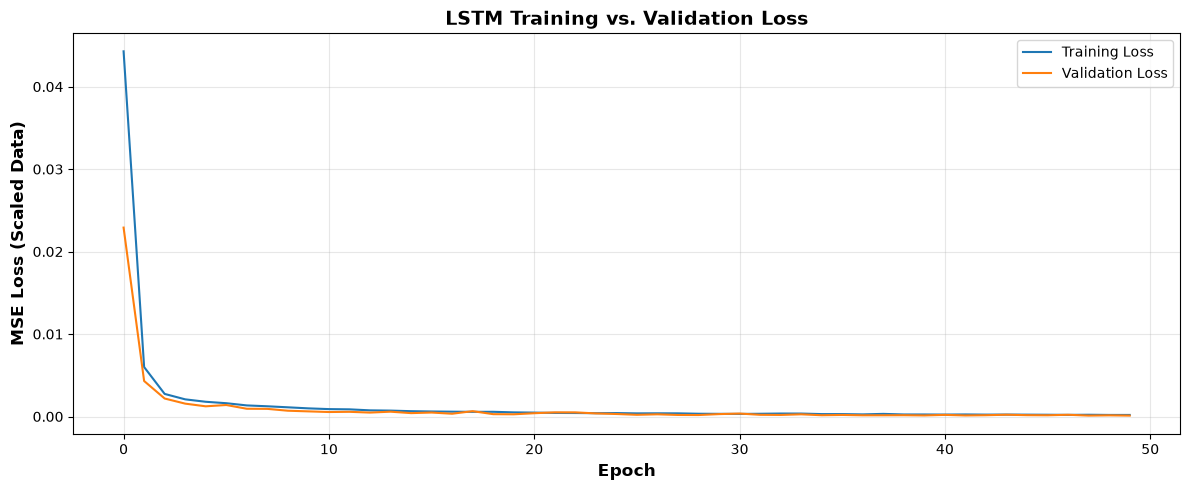

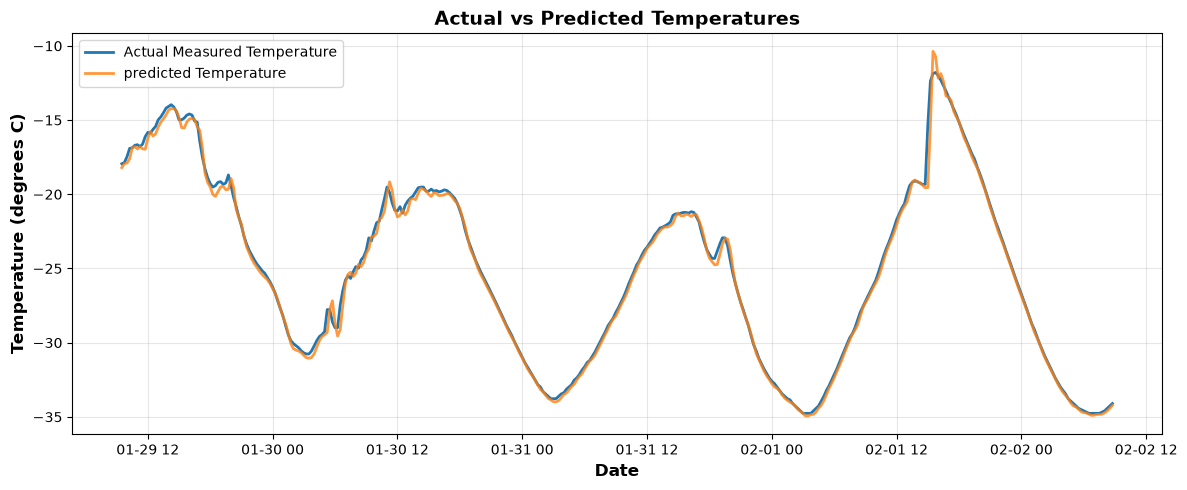

In [22]:
### training loss vs. validation loss to check for overfitting
plt.figure(figsize=(12, 5))
plt.plot(epoch_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('LSTM Training vs. Validation Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12, fontweight='bold')
plt.ylabel('MSE Loss (Scaled Data)', fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### actual vs. predicted values on test set
test_dates = test_set.index[:len(all_test_predictions)]
plt.figure(figsize=(12, 5))
plt.plot(test_dates, all_test_labels, label='Actual Measured Temperature', linewidth=2)
plt.plot(test_dates, all_test_predictions, label='predicted Temperature', linewidth=2, alpha=0.8)
plt.title('Actual vs Predicted Temperatures', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12, fontweight='bold')
plt.ylabel('Temperature (degrees C)', fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [23]:
test_dates

DatetimeIndex(['2019-01-29 09:30:00', '2019-01-29 09:45:00',
               '2019-01-29 10:00:00', '2019-01-29 10:15:00',
               '2019-01-29 10:30:00', '2019-01-29 10:45:00',
               '2019-01-29 11:00:00', '2019-01-29 11:15:00',
               '2019-01-29 11:30:00', '2019-01-29 11:45:00',
               ...
               '2019-02-02 06:30:00', '2019-02-02 06:45:00',
               '2019-02-02 07:00:00', '2019-02-02 07:15:00',
               '2019-02-02 07:30:00', '2019-02-02 07:45:00',
               '2019-02-02 08:00:00', '2019-02-02 08:15:00',
               '2019-02-02 08:30:00', '2019-02-02 08:45:00'],
              dtype='datetime64[us]', name='date_time', length=382, freq='15min')